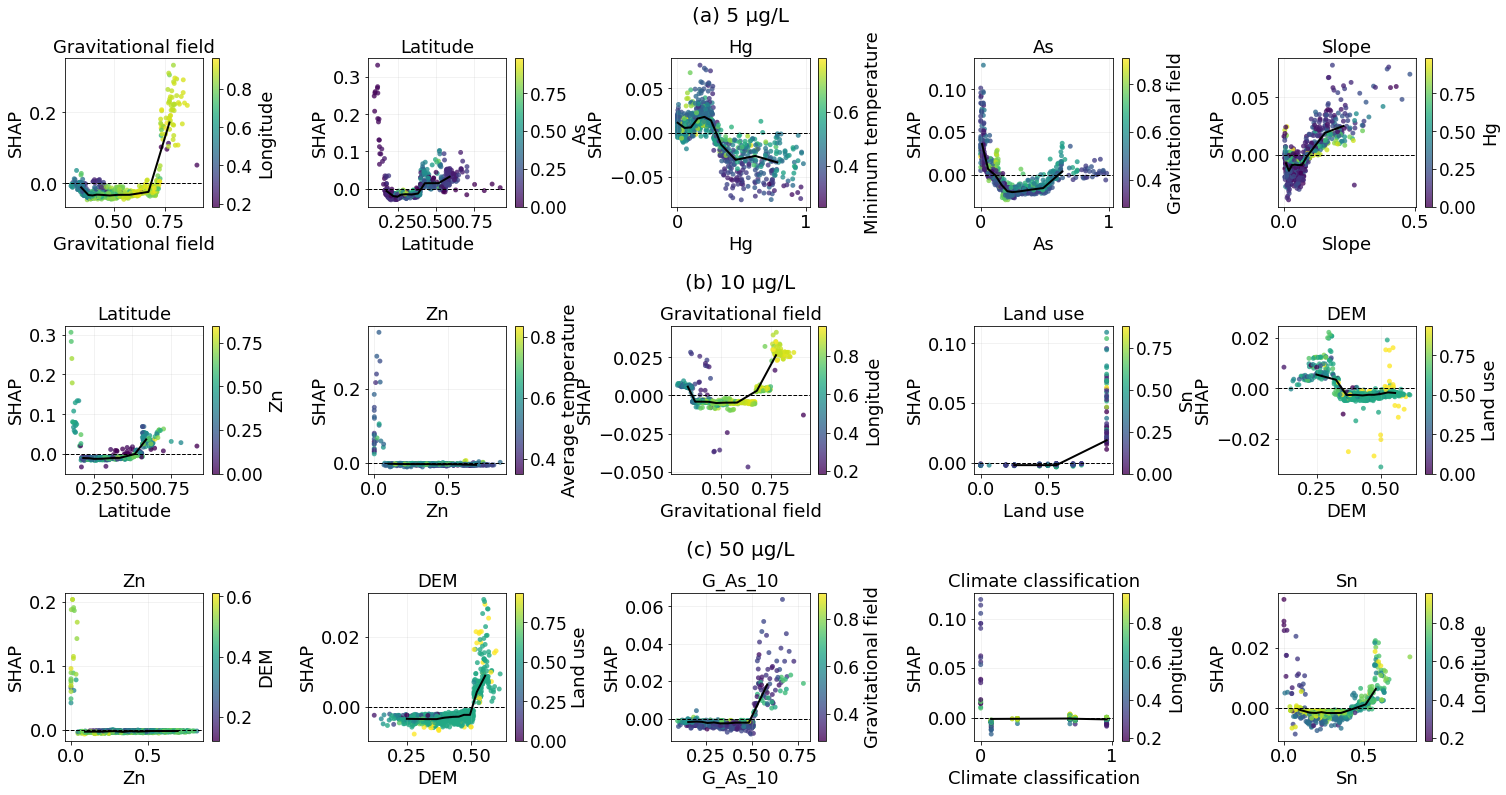

已成功输出调整后的大图：E:\NO-NC\submission\revise\SHAP_dependence_plots\SHAP_dependence_consolidated_3x5.jpg


In [16]:
# -*- coding: utf-8 -*-
"""优化版：3行5列 SHAP dependence plots 组合图（独立设置行标签与子图标题字号）"""

from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

warnings.filterwarnings("ignore")

# ==================== 全局样式与字号独立控制变量 ====================
GLOBAL_FONT_SIZE = 18       # 基础字号
TITLE_FONT_SIZE = 18        # 各子图特征变量的标题字号（保持不变）
ROW_LABEL_FONT_SIZE = 20    # 【单独调大】(a) 5 μg/L 等行标签的字号
AXIS_LABEL_FONT_SIZE = GLOBAL_FONT_SIZE   # 坐标轴标签字号
TICK_FONT_SIZE = GLOBAL_FONT_SIZE      # 坐标轴刻度字号
COLORBAR_FONT_SIZE = GLOBAL_FONT_SIZE  # Colorbar 刻度与标签字号
# ====================================================================

INPUT_DIR = Path(r"E:\NO-NC\submission\revise\SHAP_LIME_results")
OUTPUT_DIR = Path(r"E:\NO-NC\submission\revise\SHAP_dependence_plots")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

THRESHOLDS = (5, 10, 50)
TOP_N = 5
SHPS_PREFIX = "SH__" if "SH__" in locals() else "SHAP__"

def add_binned_median_trend(ax, x, y, bins=10):
    """添加按特征值分箱计算的 SHAP 中位数趋势线。"""
    data = pd.DataFrame({"x": x, "shap": y}).dropna()
    
    if len(data) < 20 or data["x"].nunique() < 4:
        return
        
    try:
        data["bin"] = pd.qcut(
            data["x"],
            q=min(bins, data["x"].nunique()),
            duplicates="drop"
        )
        trend = (
            data.groupby("bin", observed=True)
            .agg(x_median=("x", "median"),
                 shap_median=("shap", "median"))
            .dropna()
        )
        
        if len(trend) >= 2:
            ax.plot(
                trend["x_median"],
                trend["shap_median"],
                color="black",
                linewidth=2,
                label="Binned median"
            )
    except Exception:
        pass


# 创建 3行5列 的大图画布
nrows, ncols = 3, 5
fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(4.2 * ncols, 4 * nrows),
    squeeze=False
)
axes_flat = axes.ravel()

plot_idx = 0
row_labels = ["(a) 5 μg/L", "(b) 10 μg/L", "(c) 50 μg/L"]

for row_idx, threshold in enumerate(THRESHOLDS):
    input_file = (
        INPUT_DIR 
        / f"threshold_{threshold}" 
        / "full_test_shap_beeswarm_data.csv"
    )
    
    if not input_file.exists():
        raise FileNotFoundError(f"找不到 SHAP 输入文件：{input_file}")
        
    data = pd.read_csv(input_file)
    
    # 从 CSV 中识别 SHAP 列和对应的原始变量列
    shap_cols = [c for c in data.columns if c.startswith("SHAP__")]
    if not shap_cols:
        raise ValueError(f"{input_file} 中没有以 'SHAP__' 开头的 SHAP 列。")
        
    features = [c[len("SHAP__"):] for c in shap_cols]
    
    # 转为数值；非数值或缺失值按 NaN 处理
    X_df = data[features].apply(pd.to_numeric, errors="coerce")
    S_df = data[shap_cols].apply(pd.to_numeric, errors="coerce")
    S_df.columns = features
    
    # 根据完整独立测试集的 mean(|SHAP|) 排序
    importance = S_df.abs().mean(axis=0).sort_values(ascending=False)
    top_features = importance.head(min(TOP_N, len(importance))).index.tolist()
    
    # 保存该阈值的 SHAP 排名
    importance.rename("mean_abs_SHAP").to_csv(
        OUTPUT_DIR / f"SHAP_importance_{threshold}ugL.csv",
        encoding="utf-8-sig"
    )
    
    X_values = X_df.to_numpy(dtype=float)
    S_values = S_df.to_numpy(dtype=float)
    
    for col_idx in range(TOP_N):
        if plot_idx >= len(axes_flat):
            break
            
        ax = axes_flat[plot_idx]
        feature = top_features[col_idx]
        feature_idx = features.index(feature)
        x = X_df[feature].to_numpy(dtype=float)
        y = S_df[feature].to_numpy(dtype=float)
        
        valid = np.isfinite(x) & np.isfinite(y)
        color_feature = None
        
        # 近似识别可能与当前变量存在交互模式的变量，用其数值着色
        if len(features) > 1:
            try:
                interaction_order = shap.utils.approximate_interactions(
                    feature_idx,
                    S_values,
                    X_values
                )
                other_idx = next(
                    (
                        int(idx) for idx in interaction_order
                        if features[int(idx)] != feature
                    ),
                    None
                )
                if other_idx is not None:
                    color_feature = features[other_idx]
            except Exception:
                color_feature = None
                
        if color_feature is not None:
            color_values = X_df[color_feature].to_numpy(dtype=float)
            valid_color = valid & np.isfinite(color_values)
            
            points = ax.scatter(
                x[valid_color],
                y[valid_color],
                c=color_values[valid_color],
                cmap="viridis",
                s=24,
                alpha=0.78,
                edgecolors="none"
            )
            colorbar = fig.colorbar(points, ax=ax)
            colorbar.set_label(f"{color_feature}", fontsize=COLORBAR_FONT_SIZE)
            colorbar.ax.tick_params(labelsize=COLORBAR_FONT_SIZE - 1)
        else:
            ax.scatter(
                x[valid],
                y[valid],
                color="#2878B5",
                s=24,
                alpha=0.78,
                edgecolors="none"
            )
            
        # SHAP 为 0 的水平参考线
        ax.axhline(0, color="black", linewidth=1, linestyle="--")
        
        # 辅助显示变量取值与 SHAP 的总体变化趋势
        add_binned_median_trend(ax, x[valid], y[valid])
        
        # 1. 设置所有子图常规的特征名标题（字号保持 TITLE_FONT_SIZE）
        ax.set_title(f"{feature}", fontsize=TITLE_FONT_SIZE)
        
        # 2. 如果是每行的中间图（第3列，col_idx == 2），通过 ax.text 在标题上方单独绘制超大字号的行标签
        if col_idx == 2:
            ax.text(
                0.5, 1.22, 
                row_labels[row_idx], 
                transform=ax.transAxes,
                ha="center", 
                va="bottom",
                fontsize=ROW_LABEL_FONT_SIZE,
#                 fontweight="bold"
            )
            
        ax.set_xlabel(f"{feature}", fontsize=AXIS_LABEL_FONT_SIZE)
        ax.set_ylabel("SHAP", fontsize=AXIS_LABEL_FONT_SIZE)
        ax.tick_params(axis='both', labelsize=TICK_FONT_SIZE)
        ax.grid(alpha=0.2)
        
        plot_idx += 1

# 将剩余未使用的子图隐藏（如果有的话）
for i in range(plot_idx, len(axes_flat)):
    axes_flat[i].set_visible(False)

# 留出顶部空间避免行标签被裁剪
fig.tight_layout(rect=[0, 0, 1, 0.94])

output_file = OUTPUT_DIR / "SHAP_dependence_consolidated_3x5.jpg"
fig.savefig(output_file, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"已成功输出调整后的大图：{output_file}")